# Learning-order analysis

Summarizes the completed five-seed experiment and generates comparison charts. No training.

In [ ]:
import csv
import json
import math
import statistics
from pathlib import Path
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "notebooks":
    raise RuntimeError("Run this notebook from <PROJECT_ROOT>/notebooks/ only")

PROJECT_ROOT = NOTEBOOK_DIR.parent
EXPERIMENT_DIR = PROJECT_ROOT / "outputs" / "small_world" / "experiments" / "learning_order"
RESULT_PATH = EXPERIMENT_DIR / "schedule_comparison.json"
OUTPUT_DIR = EXPERIMENT_DIR / "analysis"

with RESULT_PATH.open(encoding="utf-8") as stream:
    experiment = json.load(stream)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Result:", RESULT_PATH)
print("Seeds:", experiment["config"]["seeds"])
print("Saved analysis:", OUTPUT_DIR)

Result: C:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\experiments\learning_order\schedule_comparison.json
Seeds: [42, 43, 44, 45, 46, 47, 48, 49, 50]
Saved analysis: C:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\experiments\learning_order\analysis


## 1. Check recorded runs

Verifies that all 15 runs used comparable training budgets.

In [2]:
SEEDS = sorted(experiment["config"]["seeds"])
SCHEDULES = ("mixed", "staged", "reverse")
TASKS = ("color", "shape", "pair")
RUNS = {(run["seed"], run["schedule"]): run for run in experiment["runs"]}
assert len(RUNS) == len(SEEDS) * len(SCHEDULES)
for seed in SEEDS:
    seed_runs = [RUNS[(seed, name)] for name in SCHEDULES]
    assert len({run["steps_run"] for run in seed_runs}) == 1
    assert len({run["exposure_plan"]["repetitions_per_example"] for run in seed_runs}) == 1
    assert len({run["exposure_plan"]["examples"] for run in seed_runs}) == 1
    assert len({run["final"]["id_dev"]["n"] for run in seed_runs if "n" in run["final"]["id_dev"]}) <= 1
print(f"Validated {len(RUNS)} runs, {len(SEEDS)} paired seeds, {seed_runs[0]['steps_run']} updates per model")
print("Frozen manifests:", experiment["dataset_hashes"])
print("Environment:", experiment["environment"])

Validated 27 runs, 9 paired seeds, 450 updates per model
Frozen manifests: {'train.jsonl': '49887fa41e1d31eaaea18b9c56d5a8f238e2cf05a8aef9e66418a4fee805c89b', 'id_dev.jsonl': 'bcb98cdac003c62da68b3829459a737ab8c6d9a8d60bdc29e87ee4b5a63692c9'}
Environment: {'torch': '2.13.0+cu130', 'cuda_build': '13.0', 'cuda_available': True, 'num_threads': 4, 'device_name': 'NVIDIA GeForce RTX 5050 Laptop GPU', 'capability': [12, 0]}


## 2. Summarize accuracy

Reports accuracy and loss for each schedule and seed.

In [3]:
records = []
for seed in SEEDS:
    for schedule in SCHEDULES:
        dev = RUNS[(seed, schedule)]["final"]["id_dev"]
        record = {"seed": seed, "schedule": schedule,
                  "overall_pct": 100 * dev["accuracy"], "cross_entropy": dev["loss"],
                  "swap_flip_pct": 100 * RUNS[(seed, schedule)]["paired_counterfactual"]["prediction_flip_rate"]}
        record.update({f"{task}_pct": 100 * dev["by_template"][task] for task in TASKS})
        records.append(record)
with (OUTPUT_DIR / "accuracy_by_seed.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)
for schedule in SCHEDULES:
    subset = [r for r in records if r["schedule"] == schedule]
    values = [r["pair_pct"] for r in subset]
    overall = [r["overall_pct"] for r in subset]
    print(f"{schedule:8s} binding={statistics.mean(values):5.1f}% ± {statistics.stdev(values):4.1f} pp; overall={statistics.mean(overall):5.1f}%")

mixed    binding= 69.7% ±  5.1 pp; overall= 79.9%
staged   binding= 71.9% ±  9.2 pp; overall= 79.8%
reverse  binding= 65.3% ±  9.1 pp; overall= 78.0%


## 3. Compare schedules

Measures paired differences in binding accuracy across seeds.

In [4]:
from scipy.stats import t
differences = []
for seed in SEEDS:
    binding = {schedule: 100 * RUNS[(seed, schedule)]["final"]["id_dev"]["by_template"]["pair"]
               for schedule in SCHEDULES}
    differences.append({"seed": seed, "staged_minus_mixed_pp": binding["staged"] - binding["mixed"],
                        "staged_minus_reverse_pp": binding["staged"] - binding["reverse"],
                        "mixed_minus_reverse_pp": binding["mixed"] - binding["reverse"]})
with (OUTPUT_DIR / "paired_differences.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(differences[0]))
    writer.writeheader()
    writer.writerows(differences)
for field in ("staged_minus_mixed_pp", "staged_minus_reverse_pp", "mixed_minus_reverse_pp"):
    values = [r[field] for r in differences]
    mean = statistics.mean(values)
    sd = statistics.stdev(values)
    # Student's t critical value for 95% two-sided interval, df=4, applicable to the 5-seed experiment.
    margin = t.ppf(0.975, df=len(SEEDS)-1) * sd / math.sqrt(len(SEEDS))
    print(f"{field}: differences={[round(v, 2) for v in values]}; mean={mean:+.2f} pp; approximate 95% CI=[{mean-margin:+.2f}, {mean+margin:+.2f}] pp")

staged_minus_mixed_pp: differences=[10.0, 15.0, 5.0, 0.0, -7.5, -5.0, -17.5, 5.0, 15.0]; mean=+2.22 pp; approximate 95% CI=[-6.12, +10.57] pp
staged_minus_reverse_pp: differences=[5.0, 7.5, 20.0, 12.5, 10.0, -2.5, -2.5, -12.5, 22.5]; mean=+6.67 pp; approximate 95% CI=[-1.98, +15.31] pp
mixed_minus_reverse_pp: differences=[-5.0, -7.5, 15.0, 12.5, 17.5, 2.5, 15.0, -17.5, 7.5]; mean=+4.44 pp; approximate 95% CI=[-4.91, +13.80] pp


## 4. Plot binding accuracy

Shows how each schedule performs across the five seeds.

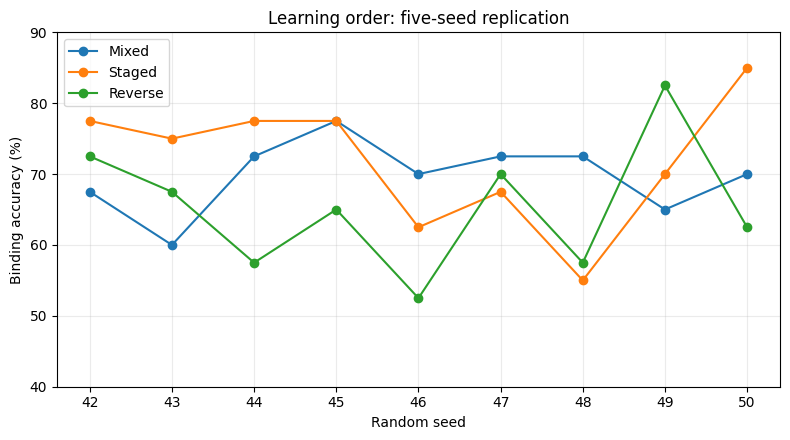

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for schedule in SCHEDULES:
    values = [100 * RUNS[(seed, schedule)]["final"]["id_dev"]["by_template"]["pair"] for seed in SEEDS]
    ax.plot(SEEDS, values, marker="o", label=schedule.capitalize())
ax.set(xlabel="Random seed", ylabel="Binding accuracy (%)", title="Learning order: five-seed replication")
ax.set_xticks(SEEDS)
ax.set_ylim(40, 90)
ax.legend()
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "binding_accuracy_by_seed.png", dpi=180)
plt.show()

## 5. Examine task interference

Tracks how binding accuracy changes during reverse training.

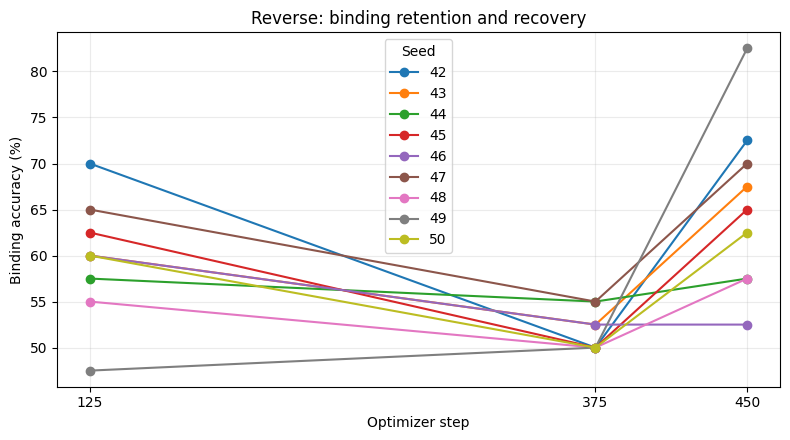

Mean change during attribute-only phase: -8.06 percentage points


In [6]:
interference = []
fig, ax = plt.subplots(figsize=(8, 4.5))
for seed in SEEDS:
    run = RUNS[(seed, "reverse")]
    checkpoints = {snap["step"]: snap["id_dev"]["by_template"]["pair"] * 100 for snap in run["history"]}
    assert all(step in checkpoints for step in (125, 375, 450))
    interference.append({"seed": seed, "after_binding_pct": checkpoints[125],
                         "after_attributes_pct": checkpoints[375], "after_rehearsal_pct": checkpoints[450],
                         "attribute_phase_change_pp": checkpoints[375] - checkpoints[125]})
    ax.plot([125, 375, 450], [checkpoints[125], checkpoints[375], checkpoints[450]], marker="o", label=str(seed))
with (OUTPUT_DIR / "reverse_task_interference.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(interference[0]))
    writer.writeheader()
    writer.writerows(interference)
ax.set(xlabel="Optimizer step", ylabel="Binding accuracy (%)", title="Reverse: binding retention and recovery")
ax.set_xticks([125, 375, 450])
ax.legend(title="Seed")
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "reverse_binding_retention.png", dpi=180)
plt.show()
print("Mean change during attribute-only phase:", round(statistics.mean(r["attribute_phase_change_pp"] for r in interference), 2), "percentage points")

## Summary

Staged outperforms reverse on binding in all five seeds, but not mixed consistently. Reverse training shows a drop in binding accuracy during attribute training. These are preliminary findings, not proof of a universally better learning schedule.